In [4]:
import numpy as np

data_fp = "../../data/mces-data/mces_distances.npz"
mces_values = None
smiles_values = None
with np.load(data_fp, allow_pickle=True) as mces_data:
    # Show the keys (column names) available in the loaded npz file
    print("Available keys (column names):", mces_data.files)
    # Show the shape of each array in the npz file
    print("Shape of 'mces' array:", mces_data['mces'].shape)
    print("Shape of 'smiles' array:", mces_data['smiles'].shape)
    mces_values = mces_data['mces'].copy()
    smiles_values = mces_data['smiles'].copy()

Available keys (column names): ['mces', 'smiles']
Shape of 'mces' array: (2012094766,)
Shape of 'smiles' array: (63437,)


In [2]:
print("\nFirst 10 rows of mces array:")
print(mces_values[:10])


First 10 rows of mces array:
[-1. -1. -1. 27. -1. -1. -1. 26. -1. -1.]


In [3]:
#Show first 10 entries of the 'smiles' array
#print("\nFirst 9 entries of smiles array:")
print(smiles_values[:9])


['[2H]C1(C([N+]2=CC=CC=C2C3=CC=CC=[N+]31)([2H])[2H])[2H].[Br-].[Br-]'
 '[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N'
 '[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.OS(=O)(=O)O'
 '[As]#[In]' 'B1(C2CCCC1CCC2)B3C4CCCC3CCC4'
 'B1(C2=C(C=C(C=C2)Cl)C=NN1S(=O)(=O)CCC)O'
 'B1(C2=C(C=C(C=C2)CNC(=O)C3=C(C=C(C=C3)C4=NOC(C4)(C5=CC(=C(C(=C5)Cl)F)Cl)C(F)(F)F)C)C(O1)(C)C)O'
 'B1(C2=CC=CC=C2C=NN1S(=O)(=O)C3=CC=C(C=C3)C)O'
 '[B-]1(=C2C=C(C=CC2=CO1)OC3=C(C=C(C=C3)CN)F)O']


In [4]:
""" NOTE THIS IS A SQUARE MATRIX
The mces_values array is a condensed distance matrix, which means it contains the upper triangle of
"""
"""
from scipy.spatial.distance import squareform
mces_values_matrix = squareform(mces_values)
mces_values_matrix[0,0:10]
"""

'\nfrom scipy.spatial.distance import squareform\nmces_values_matrix = squareform(mces_values)\nmces_values_matrix[0,0:10]\n'

In [5]:
"""
from myopic_mces import MCES

#smiles_l = mces_data['smiles'].copy().tolist()  # Convert to list of bytes
num_smiles = len(smiles_values)

solver_options={}
solver_options['msg'] = False

mces_idx = 0
for i in range(0, 2):
    for j in range(i + 1, num_smiles):
        #MCES(smiles_values[i], smiles_values[j])
        if mces_values[mces_idx] > 0:
            mces = MCES(smiles_values[i], smiles_values[j], solver_options = solver_options)
            if mces[1] != mces_values[mces_idx]:
                print(f"Mismatch for {smiles_values[i]} and {smiles_values[j]}: computed {mces[1]}, expected {mces_values[mces_idx]}")
            #print(f"MCES between {smiles_values[i]} and {smiles_values[j]}: {mces[1]},  mces_values[{mces_idx}] = {mces_values[mces_idx]}")
        mces_idx += 1
        """

'\nfrom myopic_mces import MCES\n\n#smiles_l = mces_data[\'smiles\'].copy().tolist()  # Convert to list of bytes\nnum_smiles = len(smiles_values)\n\nsolver_options={}\nsolver_options[\'msg\'] = False\n\nmces_idx = 0\nfor i in range(0, 2):\n    for j in range(i + 1, num_smiles):\n        #MCES(smiles_values[i], smiles_values[j])\n        if mces_values[mces_idx] > 0:\n            mces = MCES(smiles_values[i], smiles_values[j], solver_options = solver_options)\n            if mces[1] != mces_values[mces_idx]:\n                print(f"Mismatch for {smiles_values[i]} and {smiles_values[j]}: computed {mces[1]}, expected {mces_values[mces_idx]}")\n            #print(f"MCES between {smiles_values[i]} and {smiles_values[j]}: {mces[1]},  mces_values[{mces_idx}] = {mces_values[mces_idx]}")\n        mces_idx += 1\n        '

In [6]:
from numpy import triu_indices, sqrt
n = 10
for k in range(int(n*(n-1)/2)):
    i = n - 2 - int(sqrt(-8*k + 4*n*(n-1)-7)/2.0 - 0.5)
    j = k + i + 1 - n*(n-1)/2 + (n-i)*((n-i)-1)/2
    assert np.triu_indices(n, k=1)[0][k] == i
    assert np.triu_indices(n, k=1)[1][k] == j

for i in range(n):
    for j in range(i+1, n):
        k = int(n*(n-1)/2) - int((n-i)*((n-i)-1)/2) + j - i - 1
        #print(k)
        assert triu_indices(n, k=1)[0][k] == i
        assert triu_indices(n, k=1)[1][k] == j

In [7]:
# Get unique values from the mces array
# unique_mces = np.unique(mces_values)
# print("Unique values in mces array:")
# print(unique_mces)
# print(f"Number of unique values: {len(unique_mces)}")

In [ ]:
import pandas as pd
df = pd.DataFrame({
    'mces': mces_values,
})

# Count occurrences of each unique value
value_counts = df['mces'].value_counts()
print("\nCounts of unique values in mces array:")
print(value_counts.iloc[:10])  # Display the first 10 unique values and their counts
# Count how many pairs are not -1
# not_minus_one_count = np.sum(mces_values != -1)
# total_count = len(mces_values)
# for i in unique_mces:
#    print(f"Value {i} occurs {np.sum(mces_values == i)} times, percentage: {np.sum(mces_values == i) / total_count * 100:.2f}%")


Counts of unique values in mces array:
mces
-1.0      772417143
 24.0      23916720
 23.0      23834322
 25.0      23800136
 22.0      23532112
            ...    
 645.5            1
 632.0            1
 649.0            1
 647.0            1
 674.0            1
Name: count, Length: 1268, dtype: int64


In [12]:
value_counts.sort_index(inplace=True)
value_counts

mces
-1.0      772417143
 0.0            115
 1.0           9365
 1.5              3
 2.0          27303
            ...    
 647.0            1
 648.0            2
 649.0            1
 651.0            1
 674.0            1
Name: count, Length: 1268, dtype: int64

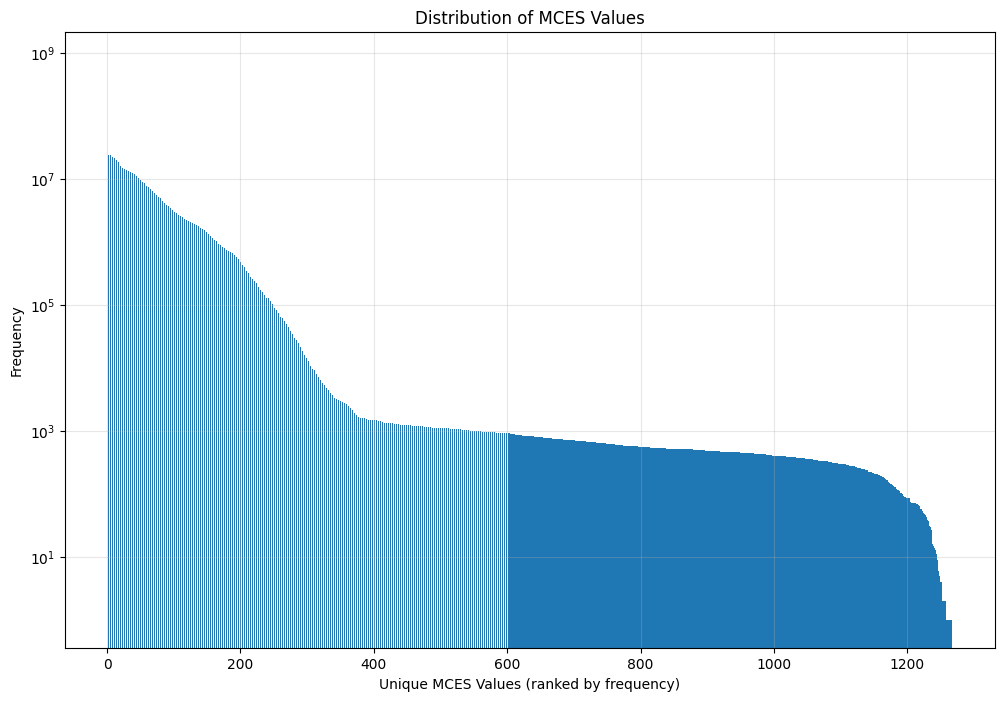

In [9]:
import matplotlib.pyplot as plt

# Create a plot showing occurrence of each unique value
plt.figure(figsize=(12, 8))
plt.bar(range(len(value_counts)), value_counts.values)
plt.xlabel('Unique MCES Values (ranked by frequency)')
plt.ylabel('Frequency')
plt.title('Distribution of MCES Values')
plt.yscale('log')  # Use log scale due to large range in frequencies
plt.grid(True, alpha=0.3)
plt.show()